# MLT Assignment #2

Student: Aleksei Chekodanov, group J4133

Music metadata with audio features of tracks from different genres (`fma_dataset_filtered.csv`, filtered version of the FMA dataset).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')
%matplotlib inline

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn import metrics

### 1. Data

In [2]:
df = pd.read_csv('fma_dataset_filtered.csv')
print(df.shape)
df.head()

(2406, 524)


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,...,0.085629,0.071289,0.000000,2.089872,0.061448,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,...,0.084578,0.063965,0.000000,1.716724,0.069330,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,...,0.053114,0.041504,0.000000,2.193303,0.044861,206,100.260,0.745566,0.701470,Hip-Hop
3,134,0.918445,0.674147,0.577818,1.281117,0.933746,0.078177,1.199204,-0.175223,0.925482,...,0.064370,0.050781,0.000000,1.806106,0.054623,207,114.290,0.513238,0.560410,Hip-Hop
4,139,-0.020869,0.432330,0.331278,0.829845,2.625593,2.005660,0.907704,0.748191,1.560385,...,0.070760,0.066895,0.000977,0.769163,0.030017,296,196.961,0.260911,0.607067,Folk


In [3]:
df['genre'].value_counts()

genre
Hip-Hop                910
Folk                   874
Old-Time / Historic    357
Classical              265
Name: count, dtype: int64

### 2. Preprocessing

- genre is the label, we do not use it as a feature, only for coloring the points and for Rand Index
- track_id is just a number, it has no information about the music
- no missing values and no duplicates
- 4 columns are constant (chroma_stft_max_04/05/07/10, always = 1), we drop them, 518 features left
- StandardScaler: the features have very different scales (spectral ones are thousands, chroma is 0..1). PCA looks at the directions with the biggest variance and K-Means uses distances, so without scaling they would see only the big features.

In [4]:
genre = df['genre'].to_numpy()
X = df.drop(columns=['track_id', 'genre'])

print('missing values:', X.isna().sum().sum())
print('duplicates:', df.duplicated().sum())

constant = X.columns[X.nunique() == 1]
print('constant columns:', list(constant))
X = X.drop(columns=constant)
print(X.shape)

missing values: 0
duplicates: 0
constant columns: ['chroma_stft_max_04', 'chroma_stft_max_05', 'chroma_stft_max_07', 'chroma_stft_max_10']
(2406, 518)


In [5]:
X_scaled = StandardScaler().fit_transform(X)

### 3. Visualization with PCA and t-SNE

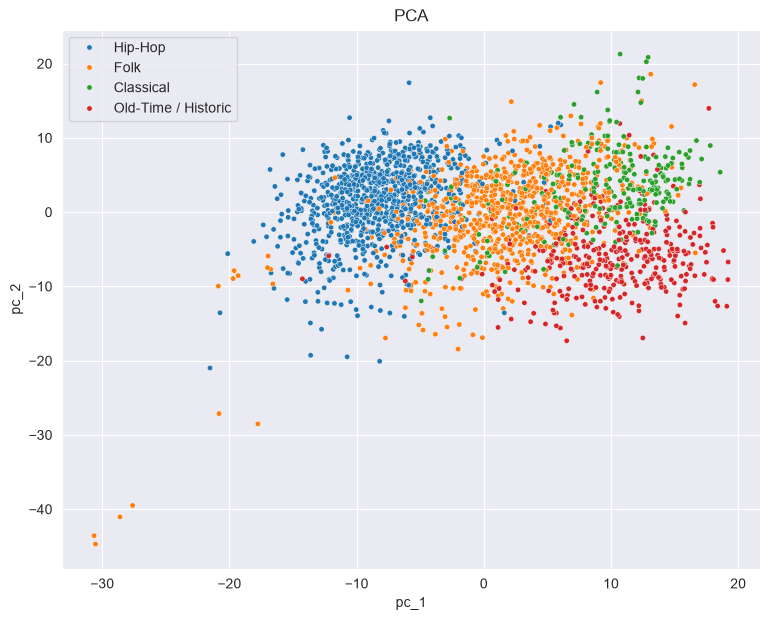

In [6]:
pca_2d = PCA(n_components=2).fit_transform(X_scaled)
pca_2d = pd.DataFrame(pca_2d, columns=['pc_1', 'pc_2'])

plt.figure(figsize=(9, 7))
sns.scatterplot(x='pc_1', y='pc_2', data=pca_2d, hue=genre, s=15)
plt.title('PCA')
plt.show()

t-SNE depends on the perplexity, let's try several values:

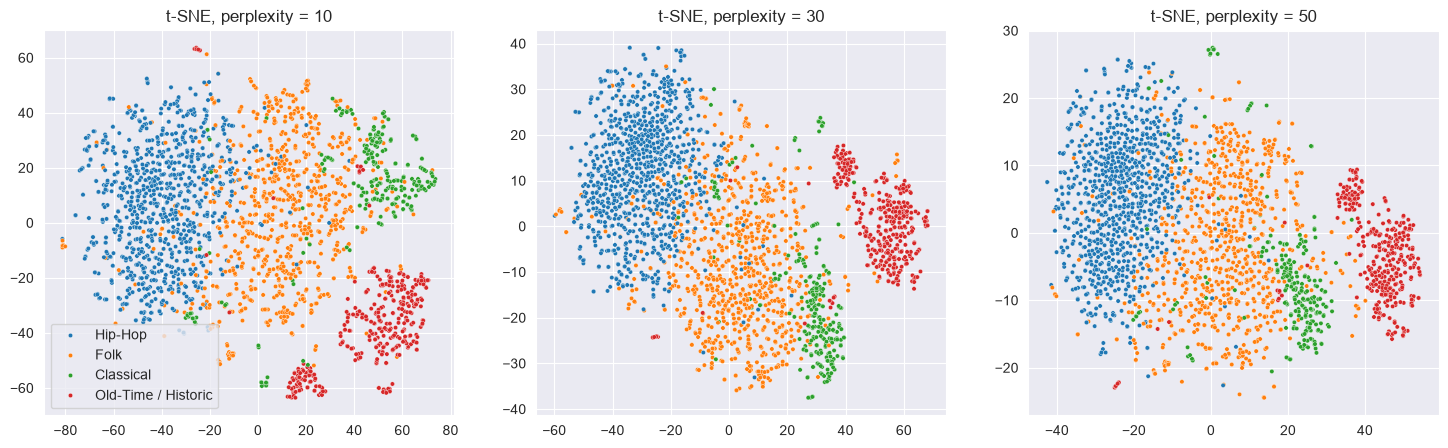

In [7]:
plt.figure(figsize=(18, 5))
for i, perplexity in enumerate([10, 30, 50]):
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=1).fit_transform(X_scaled)
    plt.subplot(1, 3, i + 1)
    sns.scatterplot(x=tsne[:, 0], y=tsne[:, 1], hue=genre, s=10, legend=(i == 0))
    plt.title('t-SNE, perplexity = {}'.format(perplexity))
plt.show()

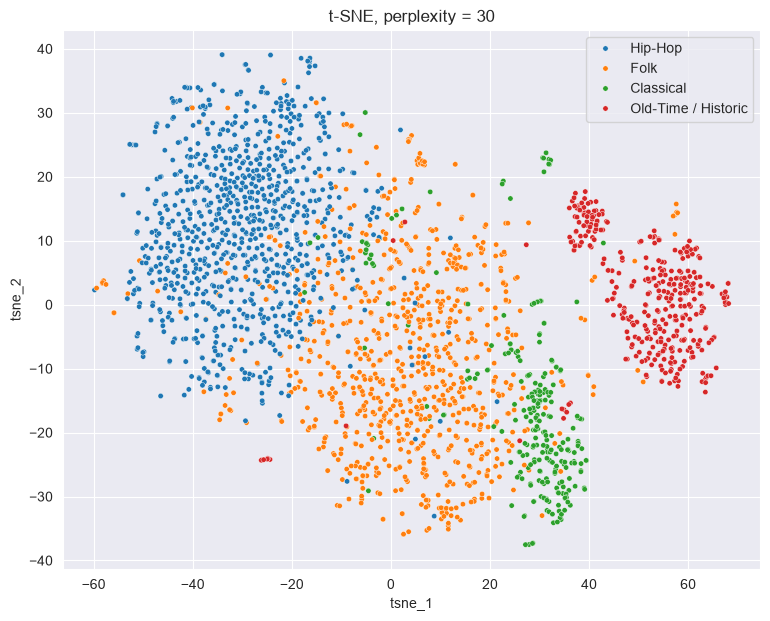

In [8]:
tsne_2d = TSNE(n_components=2, perplexity=30, random_state=1).fit_transform(X_scaled)
tsne_2d = pd.DataFrame(tsne_2d, columns=['tsne_1', 'tsne_2'])

plt.figure(figsize=(9, 7))
sns.scatterplot(x='tsne_1', y='tsne_2', data=tsne_2d, hue=genre, s=15)
plt.title('t-SNE, perplexity = 30')
plt.show()

To compare the two pictures not by eye, for every track we take its 10 nearest neighbours on the 2D plot and look how many of them have the same genre.

In [9]:
def same_genre_neighbours(data, k=10):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(data)
    idx = nn.kneighbors(data, return_distance=False)[:, 1:]  # first neighbour is the track itself
    return (genre[idx] == genre[:, None]).mean()

print('all 518 features: {:.3f}'.format(same_genre_neighbours(X_scaled)))
print('PCA 2D:           {:.3f}'.format(same_genre_neighbours(pca_2d.values)))
print('t-SNE 2D:         {:.3f}'.format(same_genre_neighbours(tsne_2d.values)))

all 518 features: 0.856
PCA 2D:           0.706
t-SNE 2D:         0.871


### 4. PCA explained variance

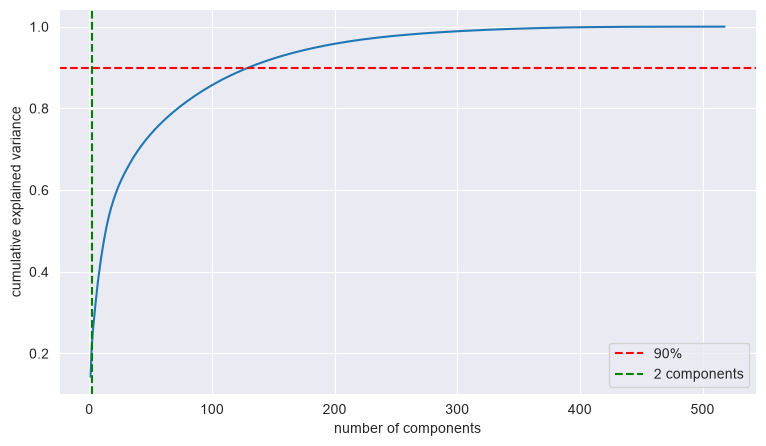

In [10]:
pca = PCA().fit(X_scaled)
explained = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(explained) + 1), explained)
plt.axhline(0.9, color='r', linestyle='--', label='90%')
plt.axvline(2, color='g', linestyle='--', label='2 components')
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.legend()
plt.show()

In [11]:
print('1 component:  {:.2%}'.format(explained[0]))
print('2 components: {:.2%}'.format(explained[1]))
print('components for 90% of variance:', np.argmax(explained >= 0.9) + 1)
print('components for 95% of variance:', np.argmax(explained >= 0.95) + 1)

1 component:  14.33%
2 components: 21.64%
components for 90% of variance: 130
components for 95% of variance: 187


### 5. K-Means

Number of clusters from 2 to 6. Silhouette uses only the data (no genres), Rand Index uses the genres. We also add the Adjusted Rand Index (ARI), it corrects Rand Index for a random split.

In [12]:
scores = []
labels = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=1)
    labels[k] = km.fit_predict(X_scaled)
    scores.append({
        'k': k,
        'silhouette': metrics.silhouette_score(X_scaled, labels[k]),
        'rand index': metrics.rand_score(genre, labels[k]),
        'adjusted rand index': metrics.adjusted_rand_score(genre, labels[k]),
        'cluster sizes': np.bincount(labels[k]),
    })

scores = pd.DataFrame(scores).set_index('k')
scores.round(4)

,silhouette,rand index,adjusted rand index,cluster sizes
k,,,,
2,0.1096,0.6803,0.3606,"[1212, 1194]"
3,0.0898,0.7854,0.5269,"[1126, 870, 410]"
4,0.0753,0.7737,0.4533,"[777, 433, 807, 389]"
5,0.0719,0.8057,0.5097,"[251, 591, 421, 776, 367]"
6,0.0739,0.8051,0.5064,"[6, 368, 415, 588, 762, 267]"


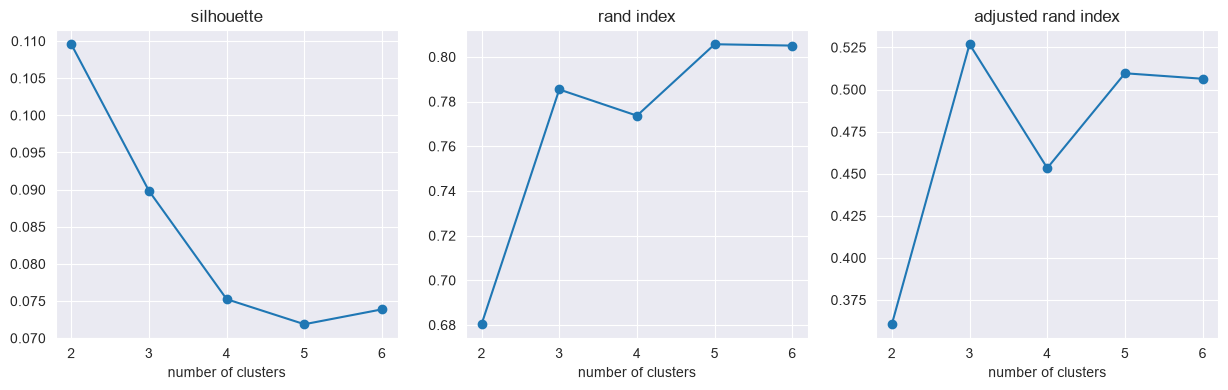

In [13]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(['silhouette', 'rand index', 'adjusted rand index']):
    plt.subplot(1, 3, i + 1)
    plt.plot(scores.index, scores[col], marker='o')
    plt.xlabel('number of clusters')
    plt.title(col)
plt.show()

In [14]:
print('best k by silhouette:', scores['silhouette'].idxmax())
print('best k by rand index:', scores['rand index'].idxmax())
print('best k by adjusted rand index:', scores['adjusted rand index'].idxmax())

best k by silhouette: 2
best k by rand index: 5
best k by adjusted rand index: 3


Which genres get into which clusters:

In [15]:
for k in [2, 5]:
    print('k =', k)
    print(pd.crosstab(genre, labels[k], rownames=['genre'], colnames=['cluster']))
    print()

k = 2
cluster                0    1
genre                        
Classical            250   15
Folk                 596  278
Hip-Hop               16  894
Old-Time / Historic  350    7

k = 5
cluster                0    1    2    3    4
genre                                       
Classical              4   38  206   11    6
Folk                  67  521  196   65   25
Hip-Hop              173   29    9  699    0
Old-Time / Historic    7    3   10    1  336



Clusters for k = 2 on the t-SNE plot:

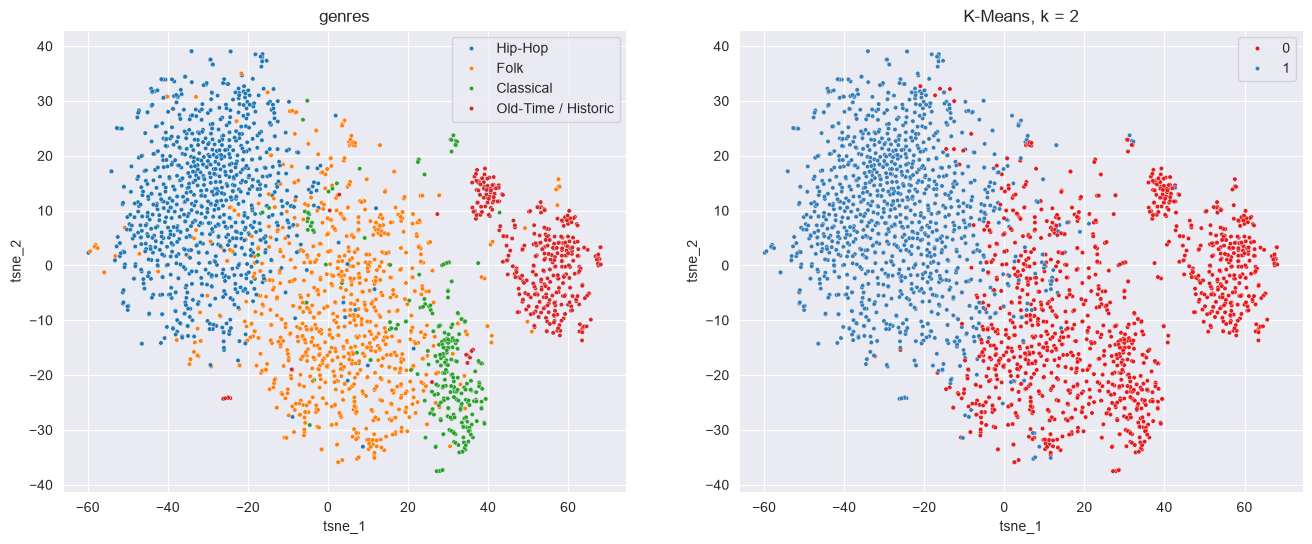

In [16]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x='tsne_1', y='tsne_2', data=tsne_2d, hue=genre, s=10)
plt.title('genres')
plt.subplot(1, 2, 2)
sns.scatterplot(x='tsne_1', y='tsne_2', data=tsne_2d, hue=labels[2], palette='Set1', s=10)
plt.title('K-Means, k = 2')
plt.show()

### Feature importance for the cluster division (for 6.5)

The data is standardized, so the feature with the biggest difference between the cluster centers is the most important one for the division.

In [17]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=1).fit(X_scaled)
center_diff = pd.Series(np.abs(km2.cluster_centers_[0] - km2.cluster_centers_[1]), index=X.columns)
center_diff.sort_values(ascending=False).head(10)

energy                         1.387927
mfcc_median_10                 1.360146
mfcc_mean_10                   1.348284
spectral_contrast_mean_04      1.318039
mfcc_max_06                    1.316341
mfcc_mean_06                   1.315376
spectral_contrast_median_04    1.313673
mfcc_median_06                 1.313279
spectral_contrast_mean_03      1.309544
mfcc_median_08                 1.304304
dtype: float64

In [18]:
X.groupby(labels[2])[['energy', 'danceability', 'tempo', 'duration']].mean()

,energy,danceability,tempo,duration
0,0.175863,0.394118,110.499054,284.366337
1,0.525827,0.588017,118.750302,200.273032


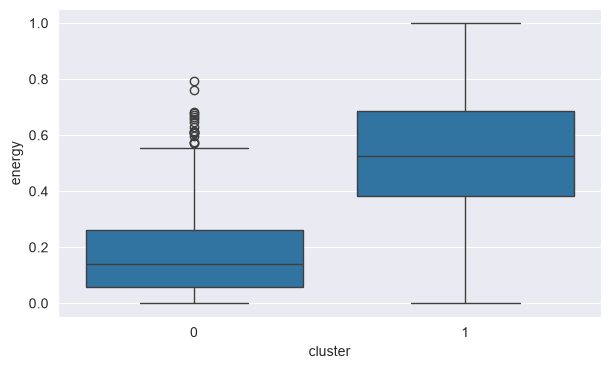

In [19]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=labels[2], y=df['energy'])
plt.xlabel('cluster')
plt.show()

### Example for 6.4: similar tracks

In [20]:
nn = NearestNeighbors(n_neighbors=6, metric='cosine').fit(X_scaled)
idx = nn.kneighbors(X_scaled, return_distance=False)[:, 1:]

print('share of the 5 most similar tracks with the same genre: {:.3f}'.format((genre[idx] == genre[:, None]).mean()))

track = 0
print('track', df['track_id'][track], '-', genre[track])
df.loc[idx[track], ['track_id', 'genre', 'energy', 'danceability', 'tempo']]

share of the 5 most similar tracks with the same genre: 0.888
track 2 - Hip-Hop


,track_id,genre,energy,danceability,tempo
343,7492,Hip-Hop,0.802764,0.814581,92.967
1710,32484,Hip-Hop,0.452812,0.398319,93.960
1706,32480,Hip-Hop,0.445807,0.379607,146.513
1734,32660,Hip-Hop,0.699752,0.443634,100.525
654,11854,Hip-Hop,0.595487,0.377231,92.525


### 6. Answers

6.1. Does the visualization from p.3 reflect the real distribution of the genres? Which algorithm is better and why?

Partly. On the PCA plot Hip-Hop is on one side and Classical / Old-Time on the other, but Folk is mixed with all the genres and many points overlap. On the t-SNE plot the groups are much clearer: Hip-Hop and Old-Time are separate, Classical and Folk are close and overlap a bit.

t-SNE is better: on the t-SNE plot 87% of the neighbours have the same genre, on PCA only 71% (in the full 518-dim space it is 86%). PCA is linear and 2 components keep only about 22% of the variance, so a lot is lost. t-SNE is non-linear and keeps close points close, that is what we need to see similar tracks. But on the t-SNE plot the distances between groups and the sizes of the groups do not mean much, and the result depends on the perplexity.

6.2. How much explained variance is left after we keep only 2 components?

21.64% (14.33% the first component and 7.31% the second). To keep 90% of the variance we need 130 components.

6.3. Can Silhouette be used to choose the number of clusters here? Is Rand Index more appropriate?

Silhouette is the best for k = 2, but its values are very small for all k (0.07 - 0.11), so the clusters are not well separated. For k = 2 K-Means splits the tracks into quiet/acoustic (Classical, Old-Time, most of Folk) and energetic (Hip-Hop and part of Folk), this is not the genre division. So Silhouette is not a good criterion here.

Rand Index is better because it uses the real genres and we want to compare the clusters with the genres. It gives k = 5 (0.806), but k = 6 is almost the same (0.805), so with another random_state it can be k = 6. And for k = 6 one cluster has only 6 tracks (outliers, you can see them in the bottom left of the PCA plot), so k = 6 is not really better. Rand Index also grows with the number of clusters, because most pairs of tracks have different genres and fall into different clusters. ARI corrects this and gives k = 3 (0.527). Of course Rand Index needs the labels.

6.4. If you don't know the genre but need a song recommendation system based on similarity, what would you do?

1. Standardize the audio features, maybe reduce the dimension with PCA (for example 130 components, 90% of the variance) to remove noise and make it faster.
2. For a song that the user likes, find the nearest songs by cosine distance (k nearest neighbours) and recommend them.
3. For a big dataset we can first cluster the songs with K-Means and search the neighbours only inside the cluster.

In the example the genres were not used, but 89% of the 5 nearest tracks have the same genre, so the features really describe the music.

6.5. What is the most important feature for the cluster division?

energy. For k = 2 it has the biggest difference between the cluster centers: the mean energy is 0.18 in one cluster and 0.53 in the other. It matches the quiet vs energetic division from 6.3. Next go some MFCC and spectral contrast features, they also describe how loud and dense the sound is.